In [2]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("data/Nivel_2.csv",          # 1. correct folder
            encoding="cp1252",     # 2. Windows encoding
            skiprows=13)           # 3. skip the metadata block
print("data shape", df.shape)
df.info()
n_na = df.isna().sum().sum()
print(f"Valores faltantes: {n_na}")

data shape (60000, 8)
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Encabezado:                   60000 non-null  str    
 1   Fecha                         60000 non-null  str    
 2   Hora                          60000 non-null  str    
 3   LIT_02                        60000 non-null  float64
 4   SP_L2                         60000 non-null  float64
 5   Program:ControlProgram\CV_L2  60000 non-null  float64
 6   LIT_04                        60000 non-null  float64
 7   FIT_02                        60000 non-null  float64
dtypes: float64(5), str(3)
memory usage: 3.7 MB
Valores faltantes: 0


In [3]:
# sanity checks before dropping
assert (df["Encabezado:"] == "Datos").all()
assert df["Fecha"].nunique() == 1      # recording didn't cross midnight

# keep the time, as a number
L2_df = df.copy()
L2_df["hora"] = pd.to_timedelta(L2_df["Hora"].str.replace(";", "."))
L2_df["t_s"] = (L2_df["hora"] - L2_df["hora"].iloc[0]).dt.total_seconds()

L2_df = L2_df.drop(columns=["Encabezado:", "Fecha", "Hora", "SP_L2",
                      "Program:ControlProgram\\CV_L2"])

L2_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype          
---  ------  --------------  -----          
 0   LIT_02  60000 non-null  float64        
 1   LIT_04  60000 non-null  float64        
 2   FIT_02  60000 non-null  float64        
 3   hora    60000 non-null  timedelta64[us]
 4   t_s     60000 non-null  float64        
dtypes: float64(4), timedelta64[us](1)
memory usage: 2.3 MB


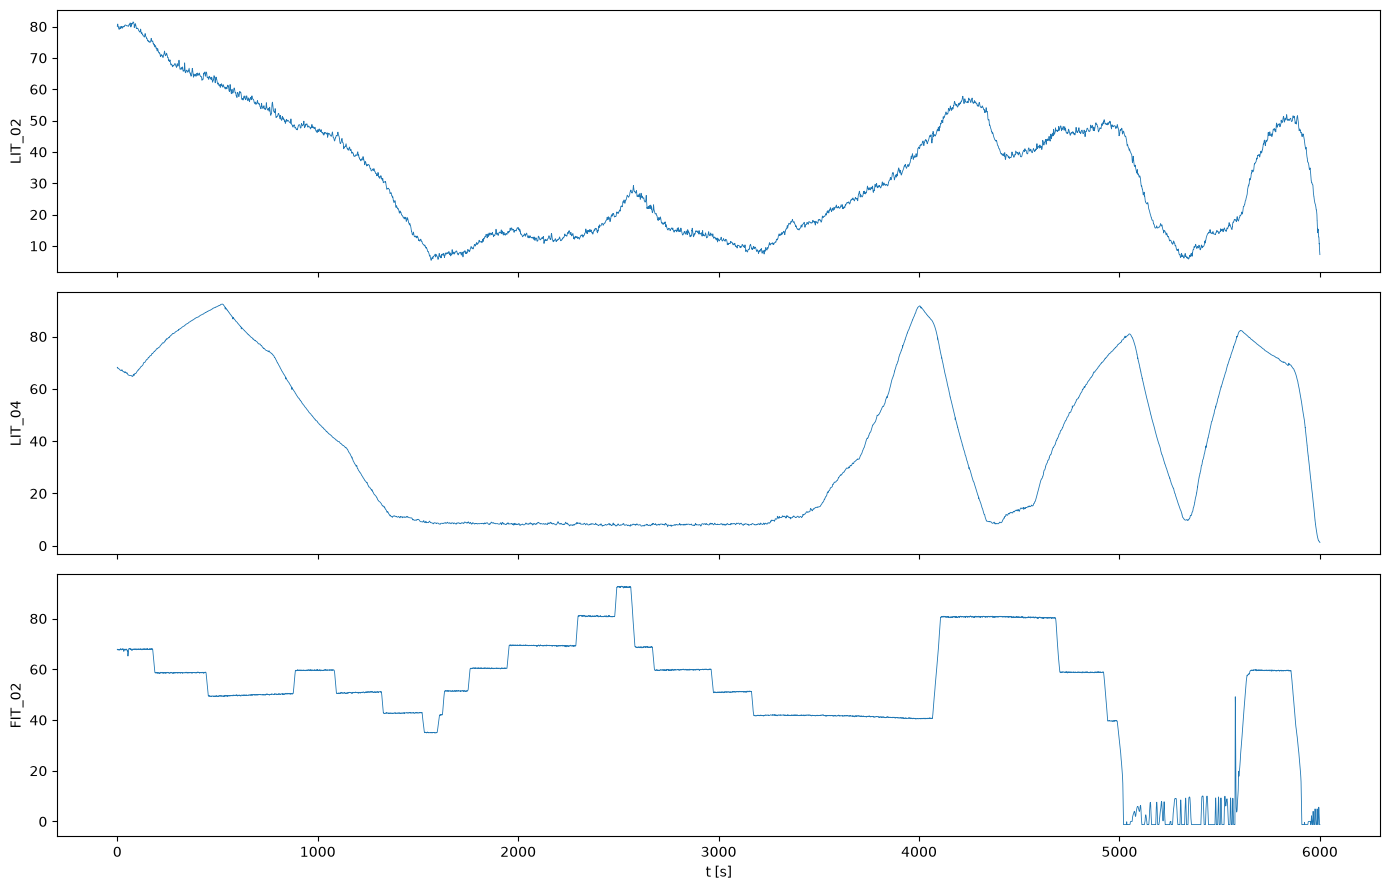

In [5]:
import matplotlib.pyplot as plt

tags = ["LIT_02", "LIT_04", "FIT_02"]
fig, axes = plt.subplots(len(tags), 1, figsize=(14, 9), sharex=True)
for ax, tag in zip(axes, tags):
    ax.plot(L2_df["t_s"], L2_df[tag], lw=0.6)
    ax.set_ylabel(tag)
axes[-1].set_xlabel("t [s]")
plt.tight_layout(); plt.show()

In [6]:
import numpy as np

def detect_errors(s, lo=0, hi=100, k=10, frozen_n=50):
    d = s.diff()
    mad = (d - d.median()).abs().median()
    thr = k * 1.4826 * mad
    out_of_range = ~s.between(lo, hi)
    spike = (d.abs() > thr) & (d.shift(-1).abs() > thr) & \
            (np.sign(d) != np.sign(d.shift(-1)))
    frozen = s.rolling(frozen_n).std() == 0
    return out_of_range, spike, frozen, thr

flags = {}
for tag in tags:
    lo = -5 if tag.startswith("FIT") else 0       # flows read slightly negative with the pump off
    r, sp, fr, thr = detect_errors(L2_df[tag], lo=lo)
    flags[tag] = r | sp | fr
    print(f"{tag}: range={r.sum()}, spikes={sp.sum()}, frozen={fr.sum()}, thr={thr:.3f}")

LIT_02: range=0, spikes=79, frozen=0, thr=0.160
LIT_04: range=0, spikes=57, frozen=0, thr=0.056
FIT_02: range=0, spikes=0, frozen=0, thr=0.155


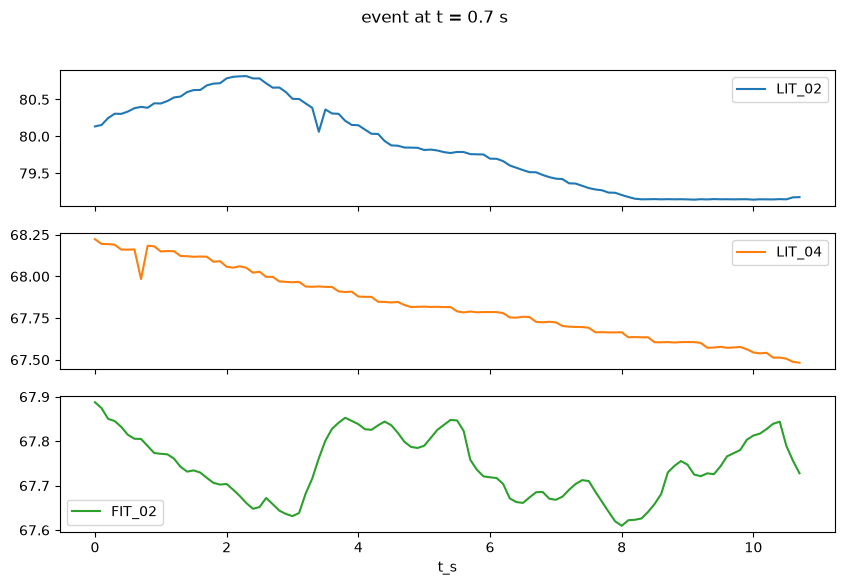

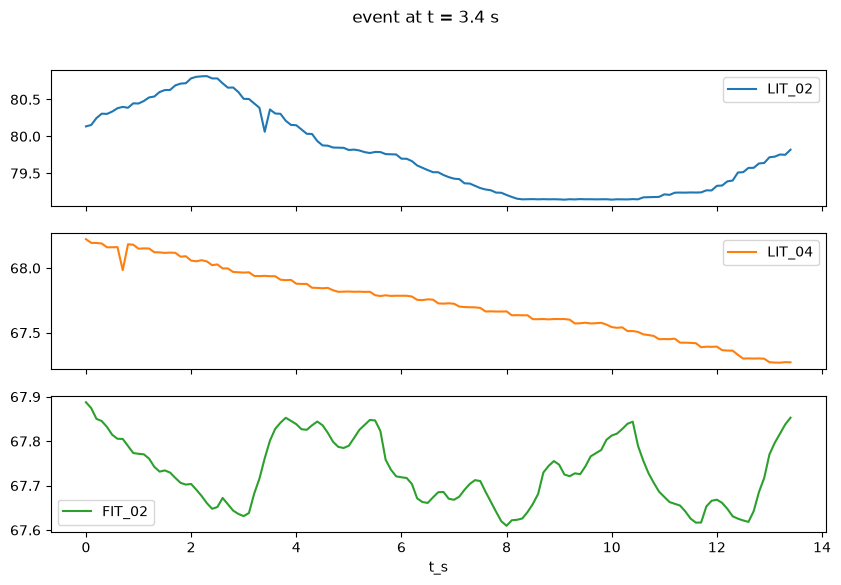

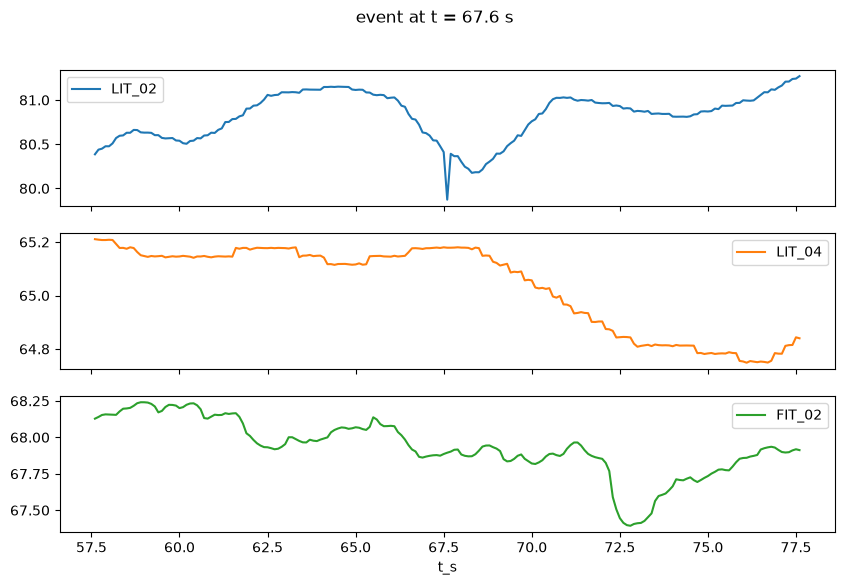

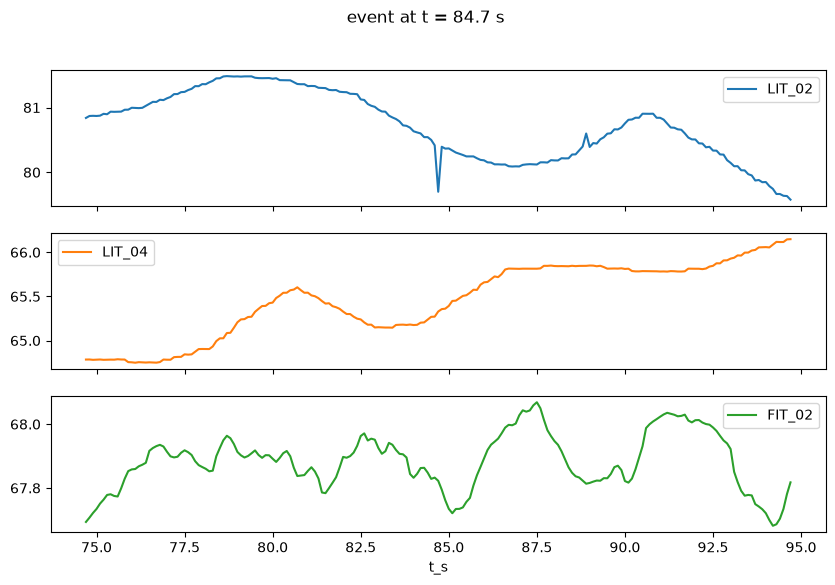

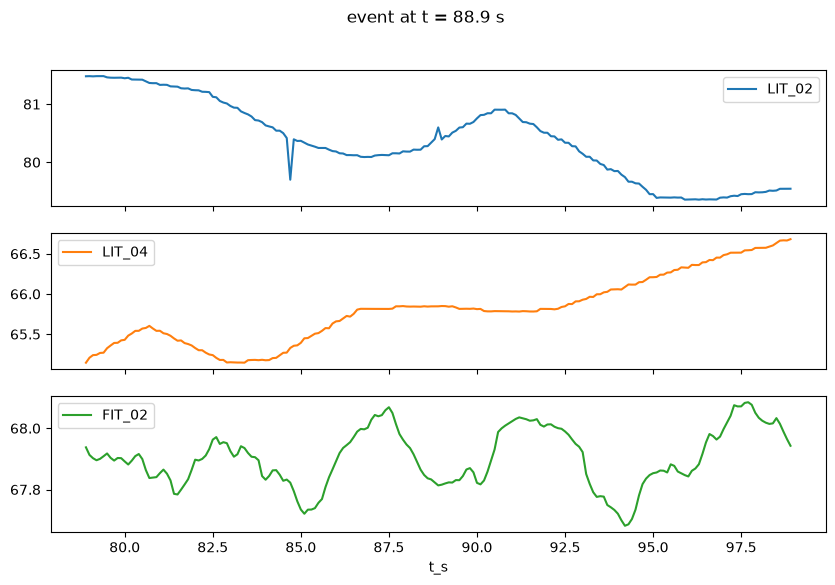

In [8]:
bad = pd.concat(flags, axis=1).any(axis=1)
events = bad & ~bad.shift(fill_value=False)          # first sample of each event
for i in L2_df.index[events][:5]:
    w = L2_df.loc[max(i-100, 0):i+100]
    w.plot(x="t_s", y=tags, subplots=True, figsize=(10, 6),
           title=f"event at t = {L2_df.at[i, 't_s']:.1f} s"); plt.show()

In [10]:
def hampel(s, window=101, k=6, min_dev=2.0):
    """Flag samples far from the rolling median.
    window: samples (101 = 10 s at 100 ms) — must be > 2× the longest glitch
    min_dev: smallest deviation (in the signal's units) ever treated as an error
    """
    med = s.rolling(window, center=True, min_periods=1).median()
    res = (s - med).abs()
    sigma = 1.4826 * res.median()          # noise level, robust to the glitches
    return res > max(k * sigma, min_dev), med

dip, med = hampel(L2_df["LIT_02"])
print("flagged:", dip.sum())
pad = 10                                              # ±1 s around each event
L2_df["valid"] = ~bad.rolling(2*pad + 1, center=True, min_periods=1).max().astype(bool)
print(f"invalid: {(~L2_df['valid']).sum()} samples")
print(100*(~L2_df['valid']).sum()/L2_df["LIT_02"].sum())

flagged: 34
invalid: 2513 samples
0.12901697809135249


### Data deistribution

In [11]:
import numpy as np

def coverage(s, bins):
    c = pd.cut(s, bins=bins, include_lowest=True).value_counts(
        normalize=True, sort=False, dropna=False) * 100
    return c.round(1)

bins = np.arange(0, 101, 20)        # assumes LIT is in %; adjust if it's cm
print(coverage(L2_df["LIT_02"], bins))
print(coverage(L2_df["LIT_04"], bins))
pd.crosstab(pd.cut(L2_df["LIT_02"], bins), pd.cut(df["LIT_04"], bins),
            normalize=True).mul(100).round(1)


LIT_02
(-0.001, 20.0]    39.6
(20.0, 40.0]      21.4
(40.0, 60.0]      29.5
(60.0, 80.0]       8.3
(80.0, 100.0]      1.1
Name: proportion, dtype: float64
LIT_04
(-0.001, 20.0]    45.1
(20.0, 40.0]      11.9
(40.0, 60.0]      11.9
(60.0, 80.0]      20.5
(80.0, 100.0]     10.6
Name: proportion, dtype: float64


LIT_04,"(0, 20]","(20, 40]","(40, 60]","(60, 80]","(80, 100]"
LIT_02,,,,,
"(0, 20]",33.9,2.3,1.7,1.4,0.3
"(20, 40]",8.3,5.5,2.5,3.6,1.6
"(40, 60]",3.0,4.0,7.7,11.2,3.6
"(60, 80]",0.0,0.0,0.0,3.2,5.1
"(80, 100]",0.0,0.0,0.0,1.1,0.0
